**1. Import Libraries**

In [ ]:

# Importing the necessary Python Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.formula.api import logit


**2. Import the data and explore it**

In [ ]:
# Importing the heart data from the CSV file
car_data = pd.read_csv('auto.csv')
car_data.tail()   # List the last 5 rows of tabular data


,mpg,cylinders,displacement,housepower,weight,acceleration,model year,origin,car name
393,27.0,4,140.0,86.00,2790,15.6,82,1,ford mustang gl
394,44.0,4,97.0,52.00,2130,24.6,82,2,vw pickup
395,32.0,4,135.0,84.00,2295,11.6,82,1,dodge rampage
396,28.0,4,120.0,79.00,2625,18.6,82,1,ford ranger
397,31.0,4,119.0,82.00,2720,19.4,82,1,chevy s-10


**3. Create a dummy variable**

Here, we create a dummy variable called 'Efficiency' using a threshold of 23(mean) of the mpg data. This means that cars with mpg of 23 and above are termed *efficient* (have the value of 1), while cars with mpg below 23 are termed *inefficient* (have the value of 0).

In [ ]:
car_data['efficiency'] = np.where(car_data['mpg'] >= 23, 1, 0)

In [ ]:
car_data.head()

,mpg,cylinders,displacement,housepower,weight,acceleration,model year,origin,car name,efficiency
0,18.0,8,307.0,130.0,3504,12.0,70,1,chevrolet chevelle malibu,0
1,15.0,8,350.0,165.0,3693,11.5,70,1,buick skylark 320,0
2,18.0,8,318.0,150.0,3436,11.0,70,1,plymouth satellite,0
3,16.0,8,304.0,150.0,3433,12.0,70,1,amc rebel sst,0
4,17.0,8,302.0,140.0,3449,10.5,70,1,ford torino,0


In [ ]:
# let us look at how many cars are efficient and inefficient.
print("Number of observations for the 'inefficient' outcome: ", (car_data['efficiency'] == 0).sum())
print("Number of observations for the 'Efficient' outcome: ", (car_data['efficiency'] == 1).sum())

Number of observations for the 'inefficient' outcome:  197
Number of observations for the 'Efficient' outcome:  201


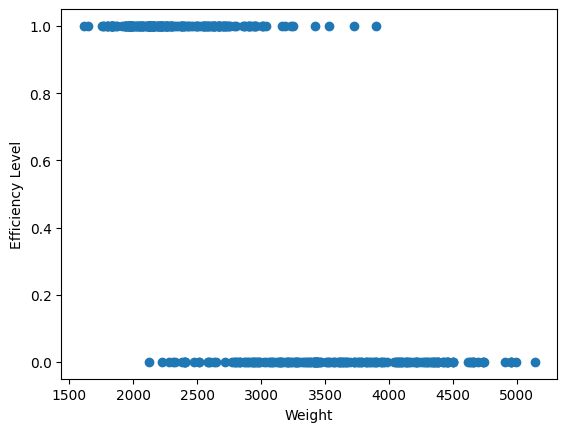

In [ ]:
# Scatter plot
plt.scatter(car_data['weight'], car_data['efficiency'])
plt.xlabel('Weight') # x-axis label
plt.ylabel('Efficiency Level') # y-axis label
plt.show()

**5. Logit Regresion Sample**

In [ ]:
# Carry out a logistic regression of the effects of weight on efficiency
car_reg = logit('efficiency ~ weight', data = car_data).fit()

Optimization terminated successfully.
         Current function value: 0.293665
         Iterations 8


In [ ]:
#Printing out the result
print(car_reg.summary())

                           Logit Regression Results                           
Dep. Variable:             efficiency   No. Observations:                  398
Model:                          Logit   Df Residuals:                      396
Method:                           MLE   Df Model:                            1
Date:                Tue, 07 Feb 2023   Pseudo R-squ.:                  0.5763
Time:                        13:25:41   Log-Likelihood:                -116.88
converged:                       True   LL-Null:                       -275.85
Covariance Type:            nonrobust   LLR p-value:                 4.055e-71
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     11.7397      1.152     10.190      0.000       9.482      13.998
weight        -0.0041      0.000    -10.043      0.000      -0.005      -0.003


Because of the underlining idea behind logistic regression, the result is interpreted in log odds, which actually does not make meaningful interpretation. One way to make a meaningful interpretation of the result is to convert it to *'odds ratio'*. To do this, we look for the exponents of the coefficients.

In [ ]:
# We look for the exponential value of the coefficients/parameters using exp function in the numpy library
np.exp(car_reg.params)

Intercept    125457.188275
weight            0.995906
dtype: float64

Now, we can interprete the coefficient in *odd ratio*. Therefore, for a unit increase in weight the odds that the car will be efficient is **0.99** times as large as the odds that the car wil be inefficient.

In [ ]:
# Here, we look at a multivariate logistic regression
car_multi_logit = car_reg = logit('efficiency ~ weight + cylinders', data = car_data).fit()

Optimization terminated successfully.
         Current function value: 0.279340
         Iterations 8


In [ ]:
#Print out the result
print(car_multi_logit.summary())

                           Logit Regression Results                           
Dep. Variable:             efficiency   No. Observations:                  398
Model:                          Logit   Df Residuals:                      395
Method:                           MLE   Df Model:                            2
Date:                Tue, 07 Feb 2023   Pseudo R-squ.:                  0.5970
Time:                        13:25:47   Log-Likelihood:                -111.18
converged:                       True   LL-Null:                       -275.85
Covariance Type:            nonrobust   LLR p-value:                 3.037e-72
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     11.5548      1.133     10.194      0.000       9.333      13.776
weight        -0.0028      0.001     -5.352      0.000      -0.004      -0.002
cylinders     -0.6795      0.209     -3.253      0.0

In [ ]:
np.exp(car_multi_logit.params)

Intercept    104272.399458
weight            0.997165
cylinders         0.506888
dtype: float64

The result means that when the weight of a car increases by 1 unit (1 pound) the odds(chances) that the car will be efficient is **0.99** times as large as the odds that the car wil be inefficient, given that the effects of cylinder is held constant. Also, when the cylinder of a car is increased by a unit, the odds (chances) that the car will be efficient is approximately **0.51** times as large as the odds that the car will be inefficient, given that the effects of weight is held constant.